In [1]:
# STEP 1 — IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score


In [2]:
# STEP 2 — LOAD THE DATASET

data = load_breast_cancer(as_frame=True)

x = data.data
y = data.target

print(x.head())
print(x.shape)
print(y.shape)


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [3]:
# STEP 3 — BASIC EDA

print(x.columns)
print(x.info())
print(x.describe())
print(x.isnull().sum().sum())
print(y.value_counts())


Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           56

In [4]:
# STEP 4 — UNDERSTAND THE TARGET
print("0 = Malignant")
print("1 = Benign")
print(y.value_counts())


0 = Malignant
1 = Benign
target
1    357
0    212
Name: count, dtype: int64


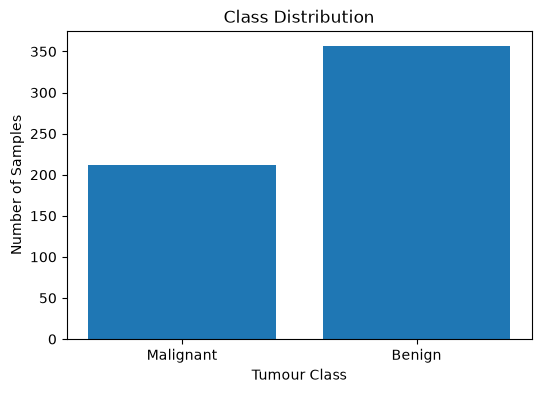

In [5]:
# STEP 5 — CLASS DISTRIBUTION
counts = y.value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(["Malignant", "Benign"], counts.values)
plt.title("Class Distribution")
plt.xlabel("Tumour Class")
plt.ylabel("Number of Samples")
plt.show()


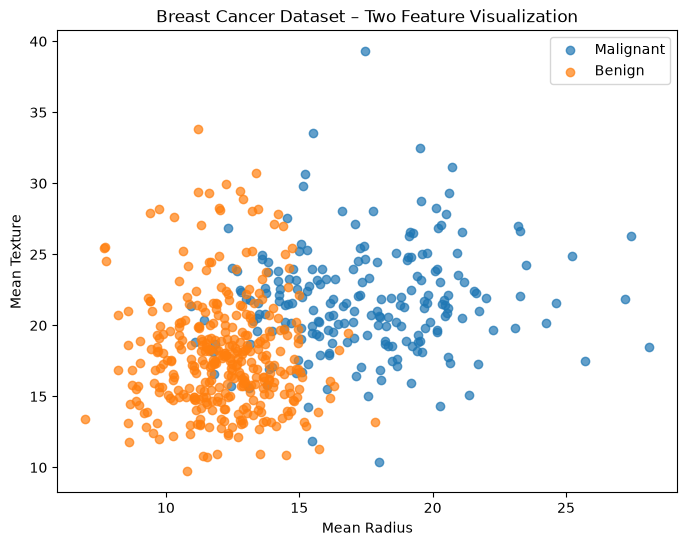

In [6]:
# STEP 6 — VISUALIZE TWO FEATURES
plt.figure(figsize=(8,6))

for target_value, label in [(0, "Malignant"), (1, "Benign")]:
    subset = x[y == target_value]
    plt.scatter(
        subset["mean radius"],
        subset["mean texture"],
        label=label,
        alpha=0.7
    )

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset – Two Feature Visualization")
plt.legend()
plt.show()


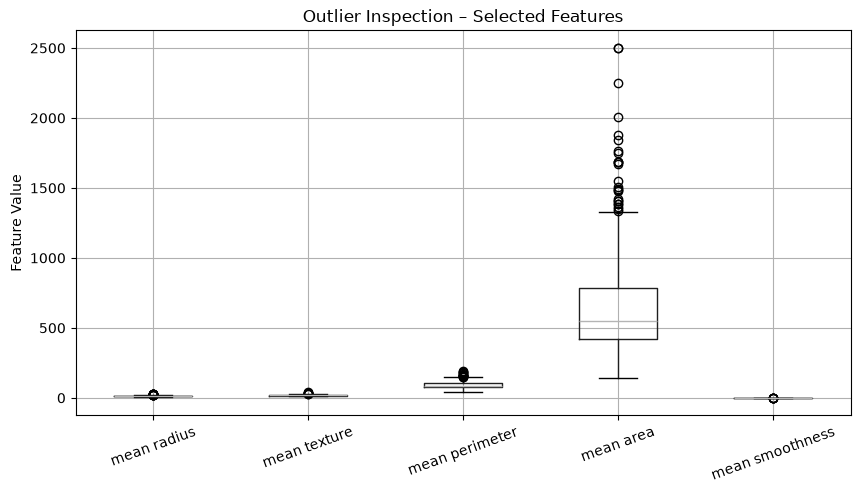

In [7]:
# STEP 7 — OUTLIER DETECTION

features_to_plot = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness"
]

plt.figure(figsize=(10,5))
x[features_to_plot].boxplot()
plt.xticks(rotation=20)
plt.title("Outlier Inspection – Selected Features")
plt.ylabel("Feature Value")
plt.show()

# We do not automatically remove outliers.
# The uploaded practical notes that removal needs domain justification.


In [8]:
# STEP 8 — TRAIN / TEST SPLIT

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)


Training data: (455, 30)
Testing data : (114, 30)


In [9]:
# STEP 9 — FEATURE SCALING
# SVM is sensitive to feature magnitude.
# Fit scaler only on training data.
# Then transform both training and testing data.

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Feature scaling completed.")


Feature scaling completed.


In [10]:
# STEP 10 — LINEAR SVM
# Linear kernel creates a straight decision boundary.

svm_linear = SVC(
    kernel="linear",
    C=1
)

svm_linear.fit(x_train_scaled, y_train)

print("Linear SVM trained successfully.")


Linear SVM trained successfully.


In [11]:
# STEP 11 — POLYNOMIAL SVM
svm_poly = SVC(
    kernel="poly",
    degree=3,
    C=1,
    gamma="scale"
)

svm_poly.fit(x_train_scaled, y_train)

print("Polynomial SVM trained successfully.")


Polynomial SVM trained successfully.


In [12]:
# STEP 12 — RBF SVM
svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

svm_rbf.fit(x_train_scaled, y_train)

print("RBF SVM trained successfully.")


RBF SVM trained successfully.


In [13]:
# STEP 13 — SUPPORT VECTORS
print("Linear SVM:", len(svm_linear.support_))
print("Polynomial SVM:", len(svm_poly.support_))
print("RBF SVM:", len(svm_rbf.support_))


Linear SVM: 32
Polynomial SVM: 145
RBF SVM: 97


In [14]:
# STEP 14 — PREDICTIONS

y_pred_linear = svm_linear.predict(x_test_scaled)
y_pred_poly = svm_poly.predict(x_test_scaled)
y_pred_rbf = svm_rbf.predict(x_test_scaled)

print("Predictions generated successfully.")


Predictions generated successfully.


In [15]:
# STEP 15 — EVALUATION FUNCTION
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_model("Linear SVM", y_test, y_pred_linear),
    evaluate_model("Polynomial SVM", y_test, y_pred_poly),
    evaluate_model("RBF SVM", y_test, y_pred_rbf)
])

print(results)


            Model  Accuracy  Precision    Recall  F1 Score
0      Linear SVM  0.973684   0.985915  0.972222  0.979021
1  Polynomial SVM  0.912281   0.878049  1.000000  0.935065
2         RBF SVM  0.982456   0.986111  0.986111  0.986111


In [16]:
# STEP 16 — CONFUSION MATRIX
matrix = confusion_matrix(y_test, y_pred_rbf)

print("Confusion Matrix:")
print(matrix)


Confusion Matrix:
[[41  1]
 [ 1 71]]


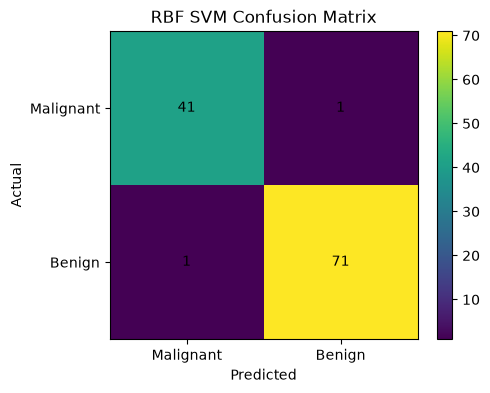

In [17]:
# STEP 17 — CONFUSION MATRIX HEATMAP
plt.figure(figsize=(5,4))

plt.imshow(matrix)
plt.title("RBF SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        plt.text(j, i, matrix[i, j], ha="center", va="center")

plt.xticks([0,1], ["Malignant", "Benign"])
plt.yticks([0,1], ["Malignant", "Benign"])
plt.show()


In [18]:
# STEP 18 — CLASSIFICATION REPORT
print(classification_report(y_test, y_pred_rbf))


              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [19]:
# STEP 19 — TWO-FEATURE DATA FOR DECISION-BOUNDARY VISUALIZATION
x_vis = x[["mean radius", "mean texture"]]

x_vis_train, x_vis_test, y_vis_train, y_vis_test = train_test_split(
    x_vis,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

vis_scaler = StandardScaler()

x_vis_train_scaled = vis_scaler.fit_transform(x_vis_train)
x_vis_test_scaled = vis_scaler.transform(x_vis_test)


In [20]:
# STEP 20 — TRAIN TWO-FEATURE MODELS FOR VISUALIZATION

vis_linear = SVC(kernel="linear", C=1)
vis_poly = SVC(kernel="poly", degree=3, C=1, gamma="scale")
vis_rbf = SVC(kernel="rbf", C=1, gamma="scale")

vis_linear.fit(x_vis_train_scaled, y_vis_train)
vis_poly.fit(x_vis_train_scaled, y_vis_train)
vis_rbf.fit(x_vis_train_scaled, y_vis_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [21]:
# STEP 21 — FUNCTION TO PLOT DECISION BOUNDARY

def plot_decision_boundary(model, x, y, title):

    x_array = np.asarray(x)
    y_array = np.asarray(y)

    x_min = x_array[:,0].min() - 1
    x_max = x_array[:,0].max() + 1
    y_min = x_array[:,1].min() - 1
    y_max = x_array[:,1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7,5))
    plt.contourf(xx, yy, z, alpha=0.20)

    plt.scatter(
        x_array[:,0],
        x_array[:,1],
        c=y_array,
        edgecolors="k",
        s=45
    )

    # Highlight support vectors
    sv = model.support_vectors_

    plt.scatter(
        sv[:,0],
        sv[:,1],
        facecolors="none",
        edgecolors="black",
        s=120,
        linewidths=1.5,
        label="Support Vectors"
    )

    plt.legend()
    plt.xlabel("Standardized Mean Radius")
    plt.ylabel("Standardized Mean Texture")
    plt.title(title)
    plt.show()


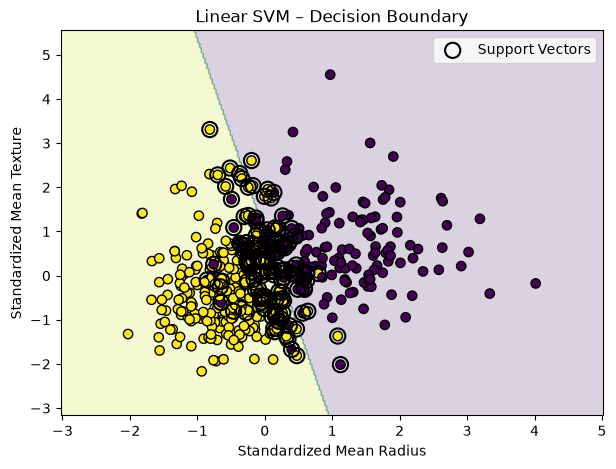

In [22]:
# STEP 22 — LINEAR SVM DECISION BOUNDARY

plot_decision_boundary(
    vis_linear,
    x_vis_train_scaled,
    y_vis_train,
    "Linear SVM – Decision Boundary"
)


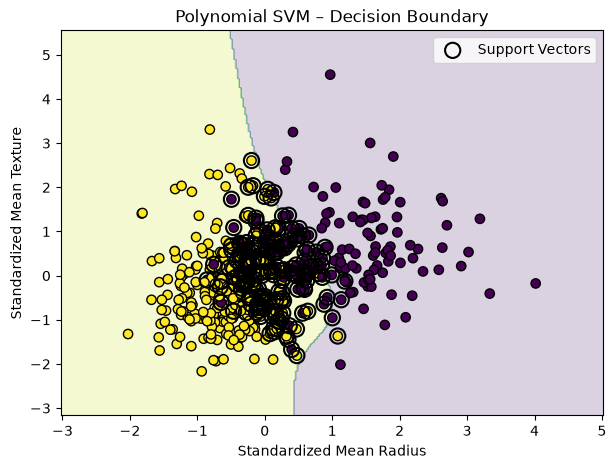

In [23]:
# STEP 23 — POLYNOMIAL SVM DECISION BOUNDARY

plot_decision_boundary(
    vis_poly,
    x_vis_train_scaled,
    y_vis_train,
    "Polynomial SVM – Decision Boundary"
)


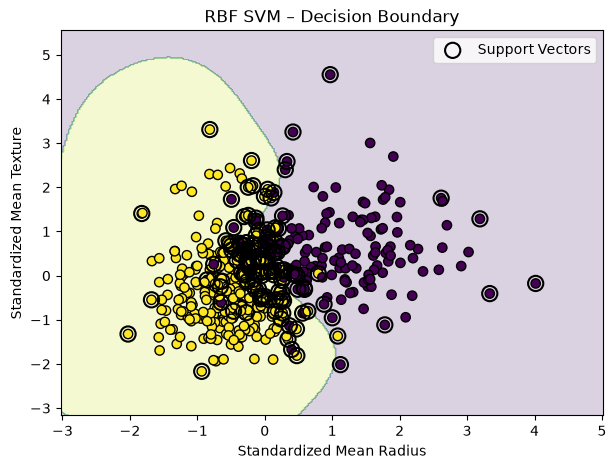

In [24]:
# STEP 24 — RBF SVM DECISION BOUNDARY

plot_decision_boundary(
    vis_rbf,
    x_vis_train_scaled,
    y_vis_train,
    "RBF SVM – Decision Boundary"
)


In [25]:
# STEP 25 — GRIDSEARCHCV HYPERPARAMETER TUNING
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = {
    "svm__kernel": ["linear", "poly", "rbf"],
    "svm__C": [0.1, 1, 10, 100],
    "svm__degree": [2, 3, 4],
    "svm__gamma": ["scale", "auto", 0.01, 0.1, 1]
}


In [27]:
# STEP 26 — RUN GRIDSEARCHCV
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score:")
print(grid_search.best_score_)
print(results)

Best Parameters:
{'svm__C': 10, 'svm__degree': 2, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}

Best Cross-Validation Score:
0.9802197802197803
            Model  Accuracy  Precision    Recall  F1 Score
0      Linear SVM  0.973684   0.985915  0.972222  0.979021
1  Polynomial SVM  0.912281   0.878049  1.000000  0.935065
2         RBF SVM  0.982456   0.986111  0.986111  0.986111
